## Dataset and Library

In [ ]:
from pathlib import Path  # Builds file paths for loading the dataset and saving outputs.
import re  # Finds or replaces text patterns, used here for email-text cleanup.
import numpy as np  # Provides numeric arrays and row-number generation.
import pandas as pd  # Loads, cleans, groups, and summarizes the tabular email dataset.

pd.set_option('display.max_colwidth', 80)  # Keep displayed table text from taking over the page.
pd.set_option('display.width', 140)  # Give printed tables more horizontal room before wrapping.

In [2]:
df = pd.read_parquet("meajor_cleaned_preprocessed.parquet.gzip")  # Load the prepared email dataset into the main table.

df.head(7)  # Display a small preview of the dataset.


sender sender_domain                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                            

## EDA — structure and data quality

In [3]:

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nFirst 5 rows:")
display(df.head())  # Show this table or preview in the notebook output.

print("\nStatistical summary:")
display(df.describe(include="all"))  # Show this table or preview in the notebook output.

Number of rows: 108685
Number of columns: 20

Column names:
['sender', 'sender_domain', 'receiver', 'receiver_domain', 'date', 'subject', 'content_types', 'body', 'urls', 'url_count', 'url_length_max', 'url_length_avg', 'url_subdom_max', 'url_subdom_avg', 'attachment_count', 'has_attachments', 'attachment_types', 'language', 'source', 'label']

Data types:
sender                  str
sender_domain           str
receiver                str
receiver_domain         str
date                    str
subject                 str
content_types           str
body                    str
urls                    str
url_count           float64
url_length_max      float64
url_length_avg      float64
url_subdom_max      float64
url_subdom_avg      float64
attachment_count    float64
has_attachments        bool
attachment_types        str
language                str
source                  str
label               float64
dtype: object

First 5 rows:


,sender,sender_domain,receiver,receiver_domain,date,subject,content_types,body,urls,url_count,url_length_max,url_length_avg,url_subdom_max,url_subdom_avg,attachment_count,has_attachments,attachment_types,language,source,label
0,d66e9e64b006d6bca649f1c945129c42c43836872b2eadfb822b6af04b3212cb,enron.com,35c5a9fb9fba3b8737ed7cef2a87e427a73db4fca85f6be4dc6a28b031887a0d,enron.com,2001-06-29 09:37:04-05:00,[ORGANIZATION] failover plan.,text/plain,"Hi [NAME], \n\nTonight we are rolling out a new report. Currently, only you and [NAME] have access to it. You'll select it off the main reports menu. It will say ""[ORGANIZATION] Download report"". When you launch it, it will show the data on screen like all other reports. There is a button at the bottom that says ""Export"". Clicking it will give you several selections. Choose the one that says ""Save to [ORGANIZATION] XML"". You can then save it as a file which can be mailed to [ORGANIZATION]. \n\nLet me know if there is anyone else who needs access.\n\nThanks!\n[NAME]",NaN,0.0,0.0,0.0,0.0,0.0,0.0,False,NaN,en,trec5,0.0
1,0907d5c64598aa2639154ed4e1556be615669e40052a1f546d692149730bdc48,enron.com,aa2c35499eae5999bf6080453cc719a891da2bb0c3803d1110bbfc60cf68f7af,enron.com,2001-06-29 08:39:30-05:00,RE: Intranet Site,text/plain,"[NAME] r these new?\tIntranet Site\n\n[NAME],\nWe need a few links to added to the [ORGANIZATION] Web Site the following links\n\n[URL]\n<|URL|>\n\n[URL]\n<|URL|>\n\n[URL]\n<|URL|>\n\nAdd the following links under daily information.\nLet me know if you have any questions.\n\nThanks,\n[NAME]",http://eastpower.dev.corp.enron.com/summary/pjmsummary.asp\nhttp://eastpower.dev.corp.enron.com/summary/nyisosummary.asp\nhttp://eastpower.dev.corp.enron.com/Cooper/MID_NYISO.ASP,3.0,60.0,58.0,3.0,3.0,0.0,False,NaN,en,trec5,0.0
2,7c3201a5ff8c5985218f1e3f11e330dc0242bbd28c6c20930a4237cfb3052988,enron.com,a736837579feb601fbf6c0657d3d93689774afa6491bb98be8b90f6327e0f6fd;765a3ec4a67e40118d22de5729b05d090a1b59cb443bf66117e3719ce9f1cac8,enron.com;enron.com,2001-06-29 10:35:17-05:00,FW: [ORGANIZATION] Company information,text/plain,"[NAME]/[NAME],\n\nWe are currently trading under GTC Spot contracts with [ORGANIZATION] for [ORGANIZATION]. Would you prefer to review their Master agreement or just send them our GISB?\n\nThanks,\n[NAME]\tRE: [ORGANIZATION] Company information\n\nJudy: Thank you for your quick response. Attached please find a copy of\nour pro forma master agreement for your review. I am filling in for the\nanalyst, [NAME], who usually handles the [ORGANIZATION] companies while he is\non vacation this week. This may be turned back to him when he returns but\nfor now, you can call me with any questions, comments or recommendations.\n\nThank you,\n[NAME]\nSr. Contract Analyst\n[ORGANIZATION]\n<|PHONE|>[ORGANIZATION] Company information\n\nJan,\n\nHere is our company information. Please let me know if you need anything\nelse.\n\n <<[FILE_NAME]>>\n\n[NAME]\n[ORGANIZATION]\n<|PHONE|>\n\n\n\n\nThis email and any files transmitted with it from the ElPaso\nCorporation are confidential and intended solely for the\nuse of the individual or entity to whom they are addressed.\nIf you have received this email in error please notify the\nsender.\n\n\n[FILE_NAME]",NaN,0.0,0.0,0.0,0.0,0.0,0.0,False,NaN,en,trec5,0.0
3,8531d54a169c4af106b9ea2165d4986b8cc10fc0a6bb9b8b114f7a0cbf9a7562,enron.com,765a3ec4a67e40118d22de5729b05d090a1b59cb443bf66117e3719ce9f1cac8;85ed1113c5015580d2336d250b36d97e485e4349b8313ebf58a48e6a0a40e736,enron.com;enron.com,2001-06-29 10:40:02-05:00,New Master Physical,text/plain,"[NAME] and [NAME] -\n\nAttached is a worksheet for a new master physical with [ORGANIZATION]. Please prepare draft at your earliest convenience and contact me when ready. I am getting the email address of the [ORGANIZATION] person to whom we need to send this.\n\n\nThanks,\n\n[NAME]",NaN,0.0,0.0,0.0,0.0,0.0,0.0,False,NaN,en,trec5,0.0
4,7c3201a5ff8c5985218f1e3f11e330dc0242bbd28c6c20930a4237cfb3052988,e


Statistical summary:


,sender,sender_domain,receiver,receiver_domain,date,subject,content_types,body,urls,url_count,url_length_max,url_length_avg,url_subdom_max,url_subdom_avg,attachment_count,has_attachments,attachment_types,language,source,label
count,108685,108191,108685,106314,108685,107230,108684,108684,64052,108685.000000,108685.000000,108685.000000,108685.000000,108685.000000,108685.000000,108685,1666,108684,108684,108684.000000
unique,55563,28464,17581,6366,107474,68486,16,103518,38352,NaN,NaN,NaN,NaN,NaN,NaN,2,145,243,3,NaN
top,2a0c86a8fa25e09e3702b5442b2a35f7b59011badd551e2933f54a159adb4cd1,enron.com,247e0a5daf10ac2f4a2ec564931b09941a066488d3fa539211df8bbdc3d825cb,enron.com,2002-03-01 04:10:35+00:00,RE:,text/plain,Start Date: [DATE]; HourAhead hour: [TIME]; No ancillary schedules awarded. No variances detected. \n\n LOG MESSAGES:\n\nPARSING FILE -->> [FILE_NAME],https://stat.ethz.ch/mailman/listinfo/r-help\nhttp://www.R-project.org/posting-guide.html,NaN,NaN,NaN,NaN,NaN,NaN,False,application/msword,en,trec5,NaN
freq,2050,21684,4484,30845,7,895,70992,667,2552,NaN,NaN,NaN,NaN,NaN,NaN,107019,383,82175,49583,NaN
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.308138,31.371091,26.691328,0.659539,0.585495,0.020785,NaN,NaN,NaN,NaN,0.441960
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10.507161,205.156377,203.959800,0.791752,0.712159,0.274444,NaN,NaN,NaN,NaN,0.496622
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,0.000000
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,0.000000
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,26.000000,24.500000,1.000000,0.208333,0.000000,NaN,NaN,NaN,NaN,0.000000
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.000000,48.000000,43.500000,1.000000,1.000000,0.000000,NaN,NaN,NaN,NaN,1.000000


In [4]:
missing_values = df.isnull().sum()  # Count missing values in each dataset column.

print("Missing values in each column:")
print(missing_values[missing_values > 0])


missing_percentage = (df.isnull().sum() / len(df)) * 100  # Calculate what percentage of each column is missing.

print("\nMissing value percentage:")
print(missing_percentage[missing_percentage > 0])

Missing values in each column:
sender_domain          494
receiver_domain       2371
subject               1455
content_types            1
body                     1
urls                 44633
attachment_types    107019
language                 1
source                   1
label                    1
dtype: int64

Missing value percentage:
sender_domain        0.454525
receiver_domain      2.181534
subject              1.338731
content_types        0.000920
body                 0.000920
urls                41.066385
attachment_types    98.467130
language             0.000920
source               0.000920
label                0.000920
dtype: float64


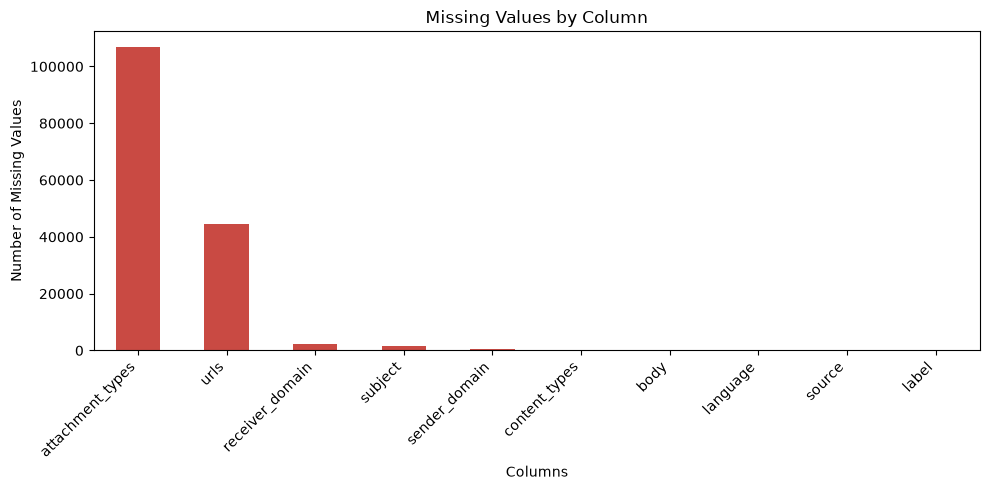

In [5]:
# Render Matplotlib plots directly below this notebook cell.
%matplotlib inline
import matplotlib.pyplot as plt  # Import Matplotlib chart functions as plt.

missing = df.isnull().sum()  # Keep only columns that contain missing values.
missing = missing[missing > 0].sort_values(ascending=False)  # Keep only columns that contain missing values.

if not missing.empty:  # Plot missing values only if any exist.
    plt.figure(figsize=(10, 5))  # Create a chart canvas before plotting data.
    missing.plot(kind="bar", color="#c94a43")  # Draw bars showing the number of missing entries in each column.
    plt.title("Missing Values by Column")  # Set the chart title.
    plt.xlabel("Columns")  # Label the horizontal axis.
    plt.ylabel("Number of Missing Values")  # Label the vertical axis.
    plt.xticks(rotation=45, ha="right")  # Set the rotation and alignment of chart labels.
    plt.tight_layout()  # Adjust spacing so chart labels are not clipped.
    plt.show()  # Render the chart in the notebook.
else:  # Run the fallback branch when the preceding condition is false.
    print("No missing values to plot.")


In [6]:
df.info()  # Show each column's type and non-missing value count.

<class 'pandas.DataFrame'>
RangeIndex: 108685 entries, 0 to 108684
Data columns (total 20 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   sender            108685 non-null  str    
 1   sender_domain     108191 non-null  str    
 2   receiver          108685 non-null  str    
 3   receiver_domain   106314 non-null  str    
 4   date              108685 non-null  str    
 5   subject           107230 non-null  str    
 6   content_types     108684 non-null  str    
 7   body              108684 non-null  str    
 8   urls              64052 non-null   str    
 9   url_count         108685 non-null  float64
 10  url_length_max    108685 non-null  float64
 11  url_length_avg    108685 non-null  float64
 12  url_subdom_max    108685 non-null  float64
 13  url_subdom_avg    108685 non-null  float64
 14  attachment_count  108685 non-null  float64
 15  has_attachments   108685 non-null  bool   
 16  attachment_types  1666 non-null

In [7]:
df.shape  # Show the number of rows and columns.

(108685, 20)

In [8]:
label_names = {0: "Benign (0)", 1: "Phishing (1)"}  # Map numeric classes to readable names.
print("Label values:", sorted(df["label"].dropna().unique().tolist()))
print("Label mapping:", label_names)


Label values: [0.0, 1.0]
Label mapping: {0: 'Benign (0)', 1: 'Phishing (1)'}


In [9]:
label_counts = df["label"].value_counts().sort_index().rename(index=label_names)  # Count the emails in each class.
print("Email counts by label:")
display(label_counts.to_frame("Emails"))  # Show this table or preview in the notebook output.
print("Share of dataset (%):")
display((label_counts / len(df) * 100).round(2).to_frame("Share (%)"))  # Show this table or preview in the notebook output.


Email counts by label:


,Emails
label,
Benign (0),60650
Phishing (1),48034


Share of dataset (%):


,Share (%)
label,
Benign (0),55.8
Phishing (1),44.2


In [10]:
missing_values = df.isna().sum().rename("Missing values").to_frame()  # Count missing values in each dataset column.
print("Missing values by column:")
display(missing_values)  # Show this table or preview in the notebook output.


Missing values by column:


,Missing values
sender,0
sender_domain,494
receiver,0
receiver_domain,2371
date,0
subject,1455
content_types,1
body,1
urls,44633
url_count,0


In [11]:
print(f"Rows available for EDA: {len(df):,}")
print(f"Missing message bodies: {df['body'].isna().sum():,}")


Rows available for EDA: 108,685
Missing message bodies: 1


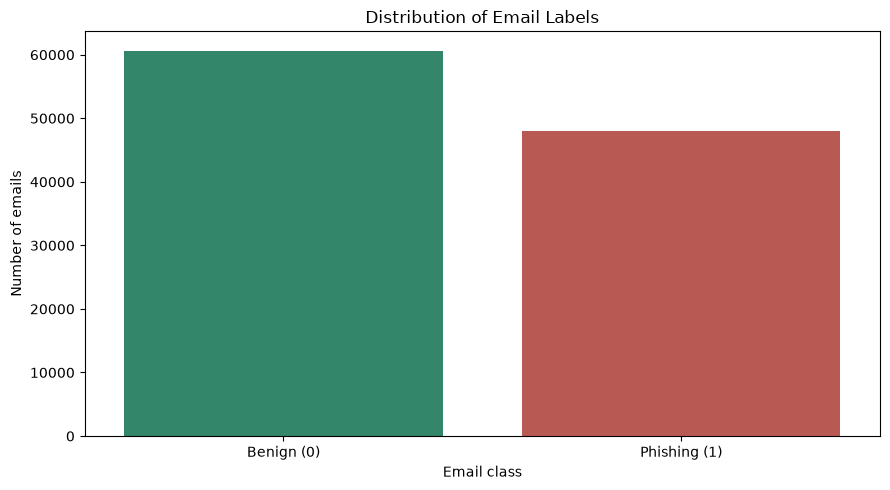

In [12]:
import matplotlib.pyplot as plt  # Import Matplotlib chart functions as plt.
import seaborn as sns  # Import Seaborn statistical charts as sns.

plot_labels = df["label"].map(label_names)  # Convert numeric labels to readable chart names.
label_order = [label_names[0], label_names[1]]  # Set the order of the classes in the chart.
label_palette = {label_names[0]: "#27936e", label_names[1]: "#c94a43"}  # Assign green to benign and red to phishing.

plt.figure(figsize=(9, 5))  # Create a chart canvas before plotting data.
sns.countplot(  # Draw bars showing the number of emails in each class.
    x=plot_labels,  # Choose data shown along the horizontal axis.
    order=label_order,  # Set category order.
    hue=plot_labels,  # Color marks by email class.
    hue_order=label_order,  # Set the order of class colors.
    palette=label_palette,  # Assign colors to classes.
    legend=False,  # Control whether a chart legend is shown.
)  # Close the list, dictionary, or function call opened above.
plt.title("Distribution of Email Labels")  # Set the chart title.
plt.xlabel("Email class")  # Label the horizontal axis.
plt.ylabel("Number of emails")  # Label the vertical axis.
plt.tight_layout()  # Adjust spacing so chart labels are not clipped.
plt.show()  # Render the chart in the notebook.


Email counts by source and label:


label,Benign (0),Phishing (1)
source,,
trec5,29929,19654
trec6,11208,3797
trec7,19513,24583


Class share within each source (%):


label,Benign (0),Phishing (1)
source,,
trec5,60.4,39.6
trec6,74.7,25.3
trec7,44.3,55.7


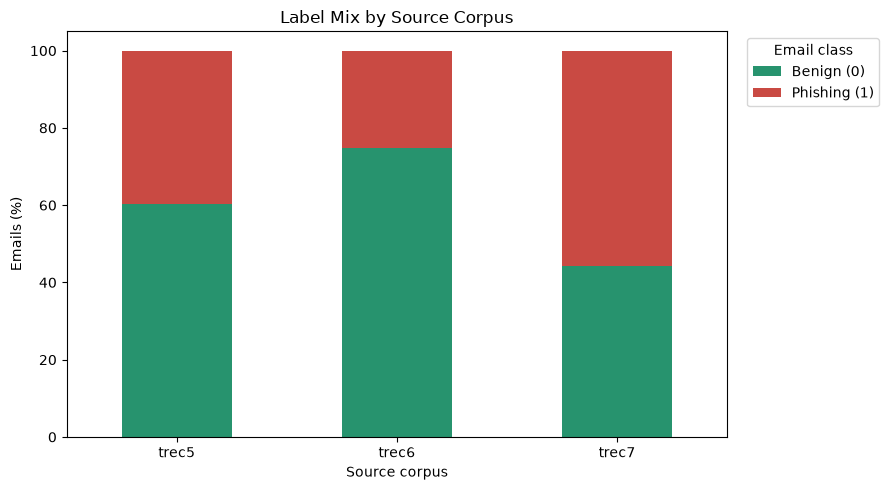

In [13]:
source_label_counts = pd.crosstab(  # Count each class for every dataset source.
    df["source"].fillna("Unknown"),  # Use source names, replacing missing names with Unknown.
    df["label"],  # Use email class labels as the other cross-tabulation dimension.
    margins=False,  # Do not add total rows or columns.
).rename(columns=label_names)  # Replace numeric class column names with readable names.
print("Email counts by source and label:")
display(source_label_counts)  # Show this table or preview in the notebook output.

source_label_share = (source_label_counts.div(source_label_counts.sum(axis=1), axis=0) * 100).round(1)  # Calculate each class's percentage within each source.
print("Class share within each source (%):")
display(source_label_share)  # Show this table or preview in the notebook output.

ax = source_label_share.plot(  # Keep the chart axes so labels and a legend can be added.
    kind="bar",  # Choose the chart style.
    stacked=True,  # Stack class bars for comparison.
    figsize=(9, 5),  # Set the chart's width and height.
    color=["#27936e", "#c94a43"],  # Choose the chart color.
)  # Close the list, dictionary, or function call opened above.
ax.set_title("Label Mix by Source Corpus")  # Set the title on this chart.
ax.set_xlabel("Source corpus")  # Label this chart's horizontal axis.
ax.set_ylabel("Emails (%)")  # Label this chart's vertical axis.
ax.legend(title="Email class", bbox_to_anchor=(1.02, 1), loc="upper left")  # Add a key explaining the chart colors.
plt.xticks(rotation=0)  # Set the rotation and alignment of chart labels.
plt.tight_layout()  # Adjust spacing so chart labels are not clipped.
plt.show()  # Render the chart in the notebook.


In [14]:
body_characters = df["body"].fillna("").astype(str).str.len()  # Measure the character length of each email body.
print("Email body character-count statistics:")
display(body_characters.describe().round(1).to_frame("Body characters"))  # Show this table or preview in the notebook output.


Email body character-count statistics:


,Body characters
count,108685.0
mean,1168.1
std,1141.7
min,0.0
25%,380.0
50%,797.0
75%,1533.0
max,30574.0


Email body word-count statistics:


,Body words
count,108685.0
mean,171.7
std,164.9
min,0.0
25%,55.0
50%,121.0
75%,227.0
90%,416.0
95%,547.0
max,1199.0


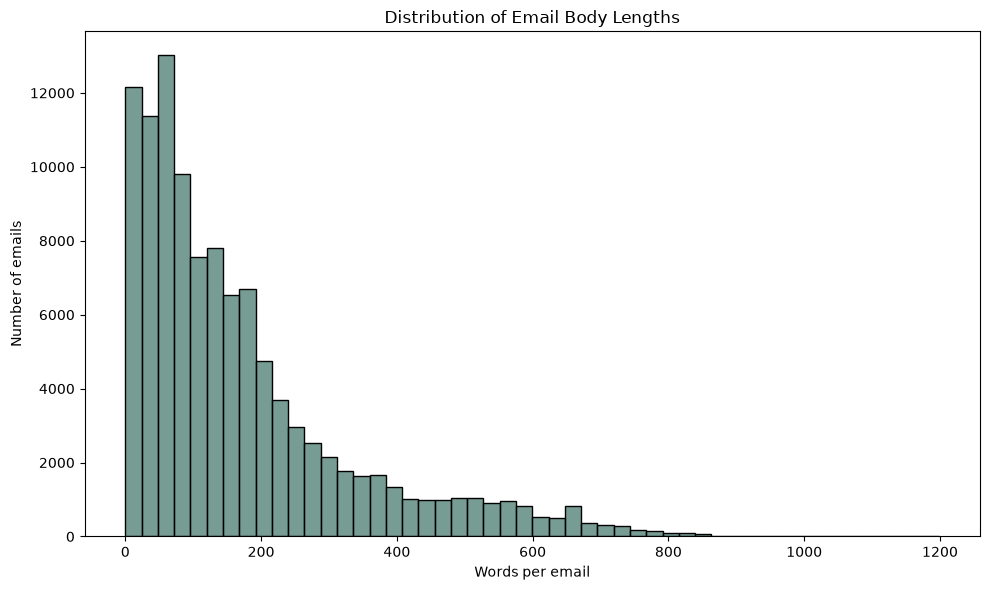

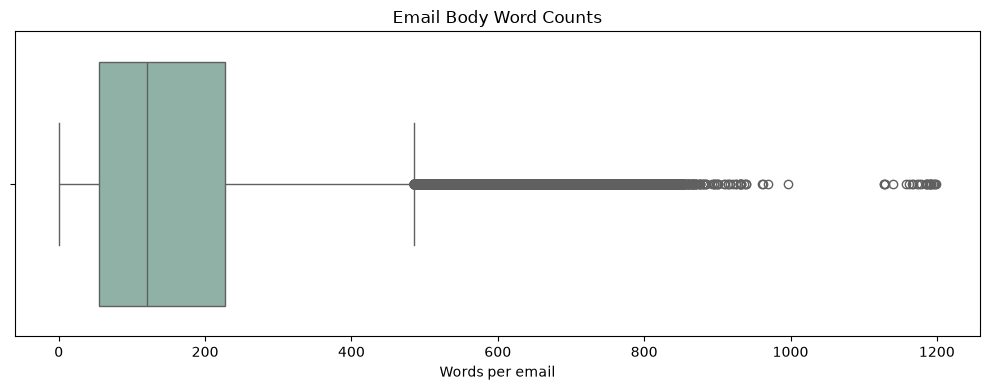

In [15]:
body_word_count = df["body"].fillna("").astype(str).str.split().str.len()  # Count the words in each email body.
print("Email body word-count statistics:")
display(body_word_count.describe(percentiles=[.25, .5, .75, .9, .95]).round(1).to_frame("Body words"))  # Show this table or preview in the notebook output.

plt.figure(figsize=(10, 6))  # Create a chart canvas before plotting data.
sns.histplot(body_word_count, bins=50, kde=False, color="#497b70")  # Draw a histogram of email lengths.
plt.title("Distribution of Email Body Lengths")  # Set the chart title.
plt.xlabel("Words per email")  # Label the horizontal axis.
plt.ylabel("Number of emails")  # Label the vertical axis.
plt.tight_layout()  # Adjust spacing so chart labels are not clipped.
plt.show()  # Render the chart in the notebook.

plt.figure(figsize=(10, 4))  # Create a chart canvas before plotting data.
sns.boxplot(x=body_word_count, color="#8ab6a6")  # Draw a box plot summarizing email-length spread.
plt.title("Email Body Word Counts")  # Set the chart title.
plt.xlabel("Words per email")  # Label the horizontal axis.
plt.tight_layout()  # Adjust spacing so chart labels are not clipped.
plt.show()  # Render the chart in the notebook.


Email subject word-count statistics:


,Subject words
count,108685.0
mean,5.3
std,3.8
min,0.0
25%,3.0
50%,5.0
75%,7.0
max,578.0


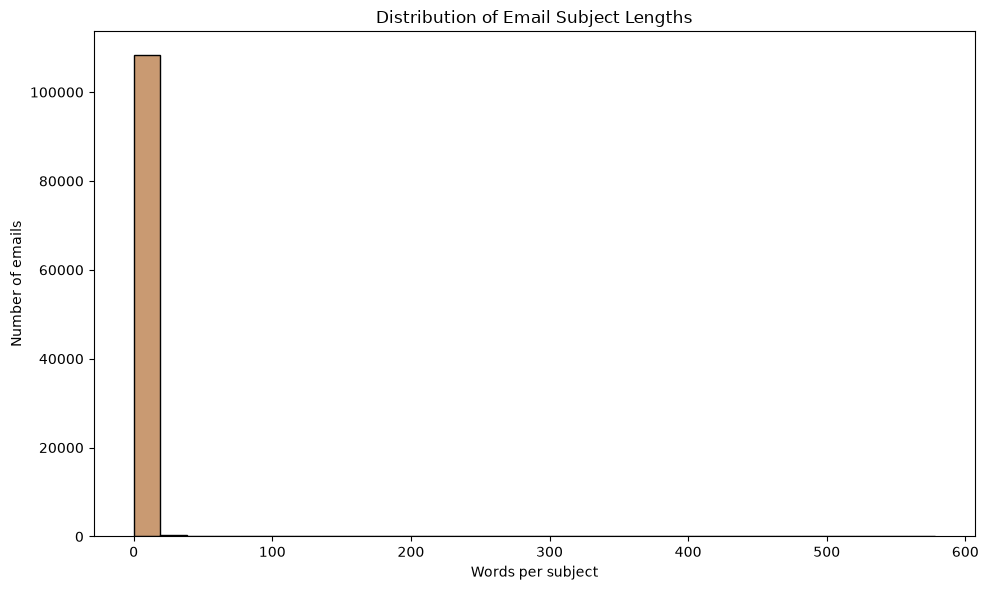

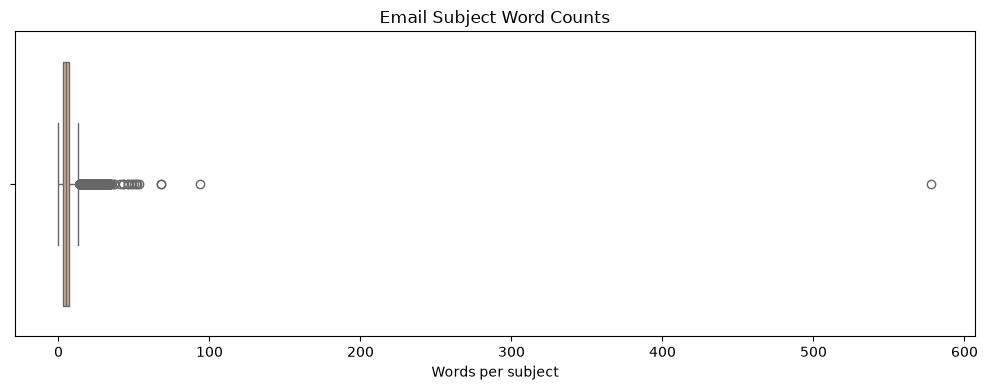

In [16]:
subject_word_count = df["subject"].fillna("").astype(str).str.split().str.len()  # Count the words in each subject.
print("Email subject word-count statistics:")
display(subject_word_count.describe().round(1).to_frame("Subject words"))  # Show this table or preview in the notebook output.

plt.figure(figsize=(10, 6))  # Create a chart canvas before plotting data.
sns.histplot(subject_word_count, bins=30, kde=False, color="#b77943")  # Draw a histogram of email lengths.
plt.title("Distribution of Email Subject Lengths")  # Set the chart title.
plt.xlabel("Words per subject")  # Label the horizontal axis.
plt.ylabel("Number of emails")  # Label the vertical axis.
plt.tight_layout()  # Adjust spacing so chart labels are not clipped.
plt.show()  # Render the chart in the notebook.

plt.figure(figsize=(10, 4))  # Create a chart canvas before plotting data.
sns.boxplot(x=subject_word_count, color="#dbad7d")  # Draw a box plot summarizing email-length spread.
plt.title("Email Subject Word Counts")  # Set the chart title.
plt.xlabel("Words per subject")  # Label the horizontal axis.
plt.tight_layout()  # Adjust spacing so chart labels are not clipped.
plt.show()  # Render the chart in the notebook.


## Preprocessing

The model input mirrors the website form: optional `From` and `Subject` headers followed by the email body. This section cleans required fields and checks duplicates; it does not train a model.

### 1. Check required fields and labels

Keep the original `df` unchanged. Remove only rows that cannot be used for supervised text classification: missing or blank bodies, or labels outside the dataset mapping of `0` (legitimate) and `1` (spam/phishing).

In [17]:
required_columns = {"sender", "sender_domain", "subject", "body", "source", "label"}  # List the columns needed for preprocessing.
missing_columns = required_columns - set(df.columns)  # Find required columns absent from the dataset.
if missing_columns:  # Stop if required dataset columns are missing.
    raise ValueError(f"Dataset is missing required columns: {sorted(missing_columns)}")  # Stop with an error explaining why this data cannot be processed.

work = df.copy()  # Copy the dataset so preprocessing leaves the EDA data unchanged.
work.insert(0, "source_row", np.arange(len(work)))  # Add a stable row number so each email can be tracked through the splits.
work["label_numeric"] = pd.to_numeric(work["label"], errors="coerce")  # Convert labels to numbers and mark invalid label text as missing.
body_for_check = work["body"].fillna("").astype(str)  # Make body values safe to check for blank text.
invalid_label = ~work["label_numeric"].isin([0, 1])  # Mark rows whose label is not 0 or 1.
empty_body = body_for_check.str.strip().eq("")  # Mark rows with a blank or whitespace-only body.
keep_row = ~invalid_label & ~empty_body  # Keep rows with valid labels and nonempty bodies.
processed = work.loc[keep_row].copy()  # Create the cleaned dataset used by later training steps.
processed["label"] = processed["label_numeric"].astype("int8")  # Store the cleaned class labels as compact integers.
print(f"Input rows: {len(work):,}")
print(f"Rows removed for missing/invalid labels: {int(invalid_label.sum()):,}")
print(f"Rows removed for empty bodies: {int(empty_body.sum()):,}")
print(f"Rows retained: {len(processed):,}")
print("Label mapping: 0 = benign; 1 = phishing")


Input rows: 108,685
Rows removed for missing/invalid labels: 1
Rows removed for empty bodies: 1
Rows retained: 108,683
Label mapping: 0 = benign; 1 = phishing


### 2. Clean fields and prepare email text

Clean optional headers, build the model input, and normalize its whitespace.

In [18]:
for column in ("sender", "sender_domain", "subject"):  # Repeat cleanup for each optional email header field.
    processed[column] = (  # Begin replacing each optional header with its cleaned version.
        processed[column]  # Read the current header field before applying cleanup.
        .fillna("")  # Replace missing values with a default.
        .astype(str)  # Convert values to the requested type.
        .str.strip()  # Trim whitespace from each string.
    )  # Close the list, dictionary, or function call opened above.

processed["body"] = processed["body"].astype(str).str.strip()  # Convert message bodies to text and trim outer whitespace.
processed["source"] = processed["source"].fillna("Unknown").astype(str).str.strip()  # Fill missing source names, convert to text, and trim whitespace.
print("Blank sender domains:", int(processed["sender_domain"].eq("").sum()))
print("Blank optional subject fields:", int(processed["subject"].eq("").sum()))


Blank sender domains: 494
Blank optional subject fields: 1455


In [19]:
def make_model_text(row):  # Define how email headers and body become model text.
    headers = []  # Start a list of email headers that are available.
    if row["sender_domain"]:  # Check this condition before running the indented block.
        headers.append(f"From: {row['sender_domain']}")  # Add the sender domain as a From header when present.
    if row["subject"]:  # Check this condition before running the indented block.
        headers.append(f"Subject: {row['subject']}")  # Add the subject header when present.
    body = row["body"]  # Read the current email body from the dataset row.
    return f"{chr(10).join(headers)}\n\n{body}" if headers else body  # Return the prepared result to the code that called this helper.

processed["model_text"] = processed.apply(make_model_text, axis=1)  # Build website-style model text for every dataset row.
display(processed[["sender_domain", "subject", "model_text", "label"]].head(3))  # Show this table or preview in the notebook output.


,sender_domain,subject,model_text,label
0,enron.com,[ORGANIZATION] failover plan.,"From: enron.com\nSubject: [ORGANIZATION] failover plan.\n\nHi [NAME], \n\nTonight we are rolling out a new report. Currently, only you and [NAME] have access to it. You'll select it off the main reports menu. It will say ""[ORGANIZATION] Download report"". When you launch it, it will show the data on screen like all other reports. There is a button at the bottom that says ""Export"". Clicking it will give you several selections. Choose the one that says ""Save to [ORGANIZATION] XML"". You can then save it as a file which can be mailed to [ORGANIZATION]. \n\nLet me know if there is anyone else who needs access.\n\nThanks!\n[NAME]",0
1,enron.com,RE: Intranet Site,"From: enron.com\nSubject: RE: Intranet Site\n\n[NAME] r these new?\tIntranet Site\n\n[NAME],\nWe need a few links to added to the [ORGANIZATION] Web Site the following links\n\n[URL]\n<|URL|>\n\n[URL]\n<|URL|>\n\n[URL]\n<|URL|>\n\nAdd the following links under daily information.\nLet me know if you have any questions.\n\nThanks,\n[NAME]",0
2,enron.com,FW: [ORGANIZATION] Company information,"From: enron.com\nSubject: FW: [ORGANIZATION] Company information\n\n[NAME]/[NAME],\n\nWe are currently trading under GTC Spot contracts with [ORGANIZATION] for [ORGANIZATION]. Would you prefer to review their Master agreement or just send them our GISB?\n\nThanks,\n[NAME]\tRE: [ORGANIZATION] Company information\n\nJudy: Thank you for your quick response. Attached please find a copy of\nour pro forma master agreement for your review. I am filling in for the\nanalyst, [NAME], who usually handles the [ORGANIZATION] companies while he is\non vacation this week. This may be turned back to him when he returns but\nfor now, you can call me with any questions, comments or recommendations.\n\nThank you,\n[NAME]\nSr. Contract Analyst\n[ORGANIZATION]\n<|PHONE|>[ORGANIZATION] Company information\n\nJan,\n\nHere is our company information. Please let me know if you need anything\nelse.\n\n <<[FILE_NAME]>>\n\n[NAME]\n[ORGANIZATION]\n<|PHONE|>\n\n\n\n\nThis email and any files transmitted with it from the ElPaso\nCorporation are confidential and intended solely for the\nuse of the individual or entity to whom they are addressed.\nIf you have received this email in error please notify the\nsender.\n\n\n[FILE_NAME]",0


In [20]:
import re  # Import regular expressions for finding and cleaning text patterns.
import unicodedata  # Import Unicode normalization for consistent text comparison.

def clean_email_text(text):  # Define a function to normalize email text.
    text = str(text)  # Convert the email text to a string before normalizing it.
    text = unicodedata.normalize("NFKC", text)  # Normalize Unicode so equivalent characters have a consistent form.
    text = re.sub(r"\s+", " ", text)  # Replace repeated whitespace with one space.
    return text.strip()  # Return the normalized text with outer whitespace removed.

In [21]:
processed["model_text"] = processed["model_text"].apply(clean_email_text)  # Normalize Unicode and whitespace in each model input.
print("Applied NFKC normalization and whitespace cleanup to model_text.")


Applied NFKC normalization and whitespace cleanup to model_text.


In [22]:
processed["model_text"] = processed["model_text"].str.strip()  # Trim whitespace around each full model input.
nonempty_model_text = processed["model_text"].str.len() > 0  # Mark combined emails that contain text.
removed_empty_model_text = int((~nonempty_model_text).sum())  # Count the blank combined emails being removed.
processed = processed.loc[nonempty_model_text].copy()  # Create the cleaned dataset used by later training steps.

print("Empty model texts removed:", removed_empty_model_text)
print(f"Rows retained after model-text check: {len(processed):,}")


Empty model texts removed: 0
Rows retained after model-text check: 108,683


In [23]:
processed["model_text_chars"] = processed["model_text"].str.len()  # Record the number of characters in each model input.
MAX_EMAIL_CHARS = 50_000  # Same limit enforced by the Flask website.
over_limit = processed["model_text_chars"].gt(MAX_EMAIL_CHARS)  # Mark emails longer than the website's input limit.

print(f"Messages over the website's {MAX_EMAIL_CHARS:,}-character limit: {int(over_limit.sum()):,}")
print("These long messages are retained in the dataset; the website itself will reject inputs above its limit.")
display(processed[["model_text", "model_text_chars", "label"]].head(3))  # Show this table or preview in the notebook output.


Messages over the website's 50,000-character limit: 0
These long messages are retained in the dataset; the website itself will reject inputs above its limit.


,model_text,model_text_chars,label
0,"From: enron.com Subject: [ORGANIZATION] failover plan. Hi [NAME], Tonight we are rolling out a new report. Currently, only you and [NAME] have access to it. You'll select it off the main reports menu. It will say ""[ORGANIZATION] Download report"". When you launch it, it will show the data on screen like all other reports. There is a button at the bottom that says ""Export"". Clicking it will give you several selections. Choose the one that says ""Save to [ORGANIZATION] XML"". You can then save it as a file which can be mailed to [ORGANIZATION]. Let me know if there is anyone else who needs access. Thanks! [NAME]",614,0
1,"From: enron.com Subject: RE: Intranet Site [NAME] r these new? Intranet Site [NAME], We need a few links to added to the [ORGANIZATION] Web Site the following links [URL] <|URL|> [URL] <|URL|> [URL] <|URL|> Add the following links under daily information. Let me know if you have any questions. Thanks, [NAME]",309,0
2,"From: enron.com Subject: FW: [ORGANIZATION] Company information [NAME]/[NAME], We are currently trading under GTC Spot contracts with [ORGANIZATION] for [ORGANIZATION]. Would you prefer to review their Master agreement or just send them our GISB? Thanks, [NAME] RE: [ORGANIZATION] Company information Judy: Thank you for your quick response. Attached please find a copy of our pro forma master agreement for your review. I am filling in for the analyst, [NAME], who usually handles the [ORGANIZATION] companies while he is on vacation this week. This may be turned back to him when he returns but for now, you can call me with any questions, comments or recommendations. Thank you, [NAME] Sr. Contract Analyst [ORGANIZATION] <|PHONE|>[ORGANIZATION] Company information Jan, Here is our company information. Please let me know if you need anything else. <<[FILE_NAME]>> [NAME] [ORGANIZATION] <|PHONE|> This email and any files transmitted with it from the ElPaso Corporation are confidential and intended solely for the use of the individual or entity to whom they are addressed. If you have received this email in error please notify the sender. [FILE_NAME]",1157,0


### 3. Check duplicates and create split groups

Create normalized duplicate keys for subjects and bodies using NFKC normalization, lowercasing, and whitespace cleanup. Report subject reuse across labels as descriptive only: subjects can be shared by different emails. `group_id` uses repeated bodies so a future split keeps copies of the same message together.


In [24]:
import re  # Import regular expressions for finding and cleaning text patterns.
import unicodedata  # Import Unicode normalization for consistent text comparison.

def normalize_for_duplicate_detection(text):  # Define a function to standardize text before duplicate checks.
    text = str(text)  # Convert the email text to a string before normalizing it.
    text = unicodedata.normalize("NFKC", text)  # Normalize Unicode so equivalent characters have a consistent form.
    text = text.lower()  # Lowercase text so capitalization does not affect duplicate matching.
    text = re.sub(r"\s+", " ", text)  # Replace repeated whitespace with one space.
    return text.strip()  # Return the normalized text with outer whitespace removed.

In [25]:
processed["subject_duplicate"] = processed["subject"].apply(  # Begin normalizing subjects for duplicate checks.
    normalize_for_duplicate_detection  # Normalize the current subject or body before comparing duplicates.
)  # Close the list, dictionary, or function call opened above.

processed["body_duplicate"] = processed["body"].apply(  # Begin normalizing bodies for duplicate checks.
    normalize_for_duplicate_detection  # Normalize the current subject or body before comparing duplicates.
)  # Close the list, dictionary, or function call opened above.

print("Created normalized duplicate keys for subject and body.")


Created normalized duplicate keys for subject and body.


In [26]:
nonempty_subjects = processed.loc[processed["subject_duplicate"].ne("")]  # Keep only rows with a nonblank normalized subject.
subject_groups = nonempty_subjects.groupby("subject_duplicate", sort=False).size()  # Count each normalized subject's occurrences.
subject_duplicate_groups = subject_groups[subject_groups > 1]  # Keep subjects that occur more than once.
subject_duplicates = (  # Mark rows whose nonempty subject is repeated.
    processed["subject_duplicate"].ne("")  # Exclude blank subjects from the duplicate-subject count.
    & processed["subject_duplicate"].duplicated(keep=False)  # Mark every row whose normalized subject is repeated.
)  # Close the list, dictionary, or function call opened above.

print("Rows with duplicated non-empty subjects:", int(subject_duplicates.sum()))
print("Number of repeated non-empty subjects:", len(subject_duplicate_groups))


Rows with duplicated non-empty subjects: 50951
Number of repeated non-empty subjects: 10171


In [27]:
body_groups = processed.groupby("body_duplicate", sort=False).size()  # Count each normalized body’s occurrences.
duplicate_groups = body_groups[body_groups > 1]  # Keep body groups that contain duplicates.
body_duplicates = processed["body_duplicate"].duplicated(keep=False)  # Mark every row whose normalized body is repeated.

print("Rows belonging to duplicated email bodies:", int(body_duplicates.sum()))
print("Number of repeated body groups:", len(duplicate_groups))
print("Excess repeated body rows:", int((duplicate_groups - 1).sum()))


Rows belonging to duplicated email bodies: 7170
Number of repeated body groups: 1382
Excess repeated body rows: 5788


In [28]:
subject_label_counts = (  # Count the labels attached to each normalized subject.
    nonempty_subjects.groupby("subject_duplicate")["label"]  # Group nonblank subjects to compare their labels.
    .nunique()  # Count distinct values.
)  # Close the list, dictionary, or function call opened above.

subjects_with_both_labels = subject_label_counts[  # Find subjects linked to more than one label.
    subject_label_counts > 1  # Keep subjects that are associated with multiple labels.
]  # Close the list, dictionary, or function call opened above.

print("Subjects associated with multiple labels:", len(subjects_with_both_labels))


Subjects associated with multiple labels: 169


In [29]:
label_counts_per_body = (  # Count the labels attached to each normalized body.
    processed.groupby("body_duplicate")["label"]  # Group duplicate bodies to compare their labels.
    .nunique()  # Count distinct values.
)  # Close the list, dictionary, or function call opened above.

conflicting_bodies = label_counts_per_body[  # Find duplicate bodies whose labels disagree.
    label_counts_per_body > 1  # Keep duplicate-body groups whose labels disagree.
]  # Close the list, dictionary, or function call opened above.

print("Number of body groups with conflicting labels:", len(conflicting_bodies))
if not conflicting_bodies.empty:  # Show examples only if conflicting duplicate bodies exist.
    display(conflicting_bodies.head(10).to_frame("distinct_labels"))  # Show this table or preview in the notebook output.


Number of body groups with conflicting labels: 9


,distinct_labels
body_duplicate,
<|url|> <|url|> <|url|> <|url|>,2
[address],2
[file_name],2
[financial_info],2
[name],2
[organization],2
[username],2
[username]<|email_separator|>[username],2
test,2


In [30]:
processed["group_id"] = pd.factorize(  # Begin assigning numeric group IDs to normalized email bodies.
    processed["body_duplicate"]  # Use normalized body text to decide which rows share a group.
)[0]  # Take the integer group codes produced by factorize.
print("Unique body-based split groups:", processed["group_id"].nunique())


Unique body-based split groups: 102895


### 4. Prepare model inputs and row IDs

`X` contains the cleaned email text, `y` contains the label, and `email_ids` keeps each source row aligned.

In [31]:
training_data = processed[["source_row", "source", "model_text", "label", "group_id"]].copy()  # Build the compact table of text, labels, source, and split group.
print(f"Training table rows: {len(training_data):,}")


Training table rows: 108,683


In [32]:
X = training_data["model_text"]  # Select email text as the model input.
y = training_data["label"]  # Select labels the model should learn to predict.
groups = training_data["group_id"]  # Keep duplicate-group IDs for the leakage-resistant split.
print("X rows:", len(X))
print("y rows:", len(y))
print("Unique split groups:", groups.nunique())


X rows: 108683
y rows: 108683
Unique split groups: 102895


In [33]:
email_ids = training_data["source_row"]  # The dataset does not provide a unique email ID.
email_sources = training_data["source"]  # Keep source-corpus names aligned with the emails.
print("Email IDs:", len(email_ids))
print("Source groups:", email_sources.value_counts().to_dict())


Email IDs: 108683
Source groups: {'trec5': 49582, 'trec7': 44096, 'trec6': 15005}


### 5. Create training, validation, and test sets

Use a stratified group split close to 80/10/10. `group_id` keeps duplicate email bodies in one partition, and `email_ids` stays aligned with each email.

In [34]:
from sklearn.model_selection import StratifiedGroupKFold  # Import the splitter that balances labels and keeps duplicate groups together.

outer_split = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)  # Configure the first grouped, stratified data split.
train_idx, temp_idx = next(outer_split.split(X, y, groups))  # Get indices for training and held-out data groups.

X_train = X.iloc[train_idx]  # Select the email text assigned to the training partition.
X_temp = X.iloc[temp_idx]  # Select the email text assigned to the temporary held-out partition.
y_train = y.iloc[train_idx]  # Select the class labels that correspond to the training emails.
y_temp = y.iloc[temp_idx]  # Select the class labels that correspond to the temporary held-out emails.
ids_train = email_ids.iloc[train_idx]  # Select the original row IDs that correspond to the training emails.
ids_temp = email_ids.iloc[temp_idx]  # Select the original row IDs that correspond to the temporary held-out emails.
groups_train = groups.iloc[train_idx]  # Select the duplicate-body group IDs that correspond to the training emails.
groups_temp = groups.iloc[temp_idx]  # Select the duplicate-body group IDs that correspond to the temporary held-out emails.
sources_train = email_sources.iloc[train_idx]  # Select the source-corpus names that correspond to the training emails.
sources_temp = email_sources.iloc[temp_idx]  # Select the source-corpus names that correspond to the temporary held-out emails.
temp_split = StratifiedGroupKFold(n_splits=2, shuffle=True, random_state=42)  # Configure the grouped split that divides validation and test data.
val_idx, test_idx = next(temp_split.split(X_temp, y_temp, groups_temp))  # Get indices for the validation and test partitions.

X_val = X_temp.iloc[val_idx]  # Select the email text assigned to the validation partition.
X_test = X_temp.iloc[test_idx]  # Select the email text assigned to the test partition.
y_val = y_temp.iloc[val_idx]  # Select the class labels that correspond to the validation emails.
y_test = y_temp.iloc[test_idx]  # Select the class labels that correspond to the test emails.
ids_val = ids_temp.iloc[val_idx]  # Select the original row IDs that correspond to the validation emails.
ids_test = ids_temp.iloc[test_idx]  # Select the original row IDs that correspond to the test emails.
groups_val = groups_temp.iloc[val_idx]  # Select the duplicate-body group IDs that correspond to the validation emails.
groups_test = groups_temp.iloc[test_idx]  # Select the duplicate-body group IDs that correspond to the test emails.
sources_val = sources_temp.iloc[val_idx]  # Select the source-corpus names that correspond to the validation emails.
sources_test = sources_temp.iloc[test_idx]  # Select the source-corpus names that correspond to the test emails.
print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))
print("Test rows:", len(X_test))
print("Training label counts:", y_train.value_counts().sort_index().to_dict())
print("Validation label counts:", y_val.value_counts().sort_index().to_dict())
print("Test label counts:", y_test.value_counts().sort_index().to_dict())
print("Training source counts:", sources_train.value_counts().to_dict())
print("Validation source counts:", sources_val.value_counts().to_dict())
print("Test source counts:", sources_test.value_counts().to_dict())
print("Shared body groups across partitions:", len(set(groups_train) & set(groups_val)) + len(set(groups_train) & set(groups_test)) + len(set(groups_val) & set(groups_test)))


Training rows: 86946
Validation rows: 10869
Test rows: 10868
Training label counts: {0: 48519, 1: 38427}
Validation label counts: {0: 6065, 1: 4804}
Test label counts: {0: 6065, 1: 4803}
Training source counts: {'trec5': 39660, 'trec7': 35352, 'trec6': 11934}
Validation source counts: {'trec5': 4806, 'trec7': 4451, 'trec6': 1612}
Test source counts: {'trec5': 5116, 'trec7': 4293, 'trec6': 1459}
Shared body groups across partitions: 0


In [35]:
from sklearn.feature_extraction.text import TfidfVectorizer  # Import the text-to-numeric TF-IDF feature converter.


In [36]:
tfidf = TfidfVectorizer(  # Configure how email words become numeric TF-IDF features.
    lowercase=True,  # Lowercase text before extracting words.
    stop_words=None,  # Keep common words instead of removing them.
    ngram_range=(1, 2),  # Use single words and two-word phrases.
    min_df=2,  # Ignore words seen in fewer than two training emails.
    max_df=0.98,  # Ignore words seen in more than 98% of training emails.
    sublinear_tf=True,  # Reduce the influence of repeated words.
    max_features=200000  # Limit the vocabulary to 200,000 features.
)  # Close the list, dictionary, or function call opened above.

In [37]:
X_train_tfidf = tfidf.fit_transform(X_train)  # Learn the word vocabulary from training emails and transform them.

X_val_tfidf = tfidf.transform(X_val)  # Transform validation emails using the training vocabulary.

X_test_tfidf = tfidf.transform(X_test)  # Transform test emails using the training vocabulary.

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Validation TF-IDF shape:", X_val_tfidf.shape)
print("Test TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (86946, 200000)
Validation TF-IDF shape: (10869, 200000)
Test TF-IDF shape: (10868, 200000)


### 6. Save the preprocessed training table

Export one row per usable email for later model training.

In [38]:
output_path = Path("MeAJOR_preprocessed.csv")  # Choose the CSV output path for the cleaned training table.
training_data.to_csv(output_path, index=False)  # Save the prepared training table without an extra index column.
print(f"Saved {len(training_data):,} rows to {output_path.resolve()}")
print("Training label counts:")
display(y.value_counts().sort_index().rename(index=label_names).to_frame("Emails"))  # Show this table or preview in the notebook output.
print("Saved table preview:")
display(training_data.head(5))  # Show this table or preview in the notebook output.


Saved 108,683 rows to C:\Users\LENOVO\OneDrive\Documents\Phishing Detection Website\training\MeAJOR_preprocessed.csv
Training label counts:


,Emails
label,
Benign (0),60649
Phishing (1),48034


Saved table preview:


,source_row,source,model_text,label,group_id
0,0,trec5,"From: enron.com Subject: [ORGANIZATION] failover plan. Hi [NAME], Tonight we are rolling out a new report. Currently, only you and [NAME] have access to it. You'll select it off the main reports menu. It will say ""[ORGANIZATION] Download report"". When you launch it, it will show the data on screen like all other reports. There is a button at the bottom that says ""Export"". Clicking it will give you several selections. Choose the one that says ""Save to [ORGANIZATION] XML"". You can then save it as a file which can be mailed to [ORGANIZATION]. Let me know if there is anyone else who needs access. Thanks! [NAME]",0,0
1,1,trec5,"From: enron.com Subject: RE: Intranet Site [NAME] r these new? Intranet Site [NAME], We need a few links to added to the [ORGANIZATION] Web Site the following links [URL] <|URL|> [URL] <|URL|> [URL] <|URL|> Add the following links under daily information. Let me know if you have any questions. Thanks, [NAME]",0,1
2,2,trec5,"From: enron.com Subject: FW: [ORGANIZATION] Company information [NAME]/[NAME], We are currently trading under GTC Spot contracts with [ORGANIZATION] for [ORGANIZATION]. Would you prefer to review their Master agreement or just send them our GISB? Thanks, [NAME] RE: [ORGANIZATION] Company information Judy: Thank you for your quick response. Attached please find a copy of our pro forma master agreement for your review. I am filling in for the analyst, [NAME], who usually handles the [ORGANIZATION] companies while he is on vacation this week. This may be turned back to him when he returns but for now, you can call me with any questions, comments or recommendations. Thank you, [NAME] Sr. Contract Analyst [ORGANIZATION] <|PHONE|>[ORGANIZATION] Company information Jan, Here is our company information. Please let me know if you need anything else. <<[FILE_NAME]>> [NAME] [ORGANIZATION] <|PHONE|> This email and any files transmitted with it from the ElPaso Corporation are confidential and intended solely for the use of the individual or entity to whom they are addressed. If you have received this email in error please notify the sender. [FILE_NAME]",0,2
3,3,trec5,"From: enron.com Subject: New Master Physical [NAME] and [NAME] - Attached is a worksheet for a new master physical with [ORGANIZATION]. Please prepare draft at your earliest convenience and contact me when ready. I am getting the email address of the [ORGANIZATION] person to whom we need to send this. Thanks, [NAME]",0,3
4,4,trec5,"From: enron.com Subject: FW: [ORGANIZATION]/Mirant GISB FYI. Below is a copy of my communication with [ORGANIZATION] regarding our GISB in case someone from Mirant calls regarding the contract. Thanks, Judy RE: [ORGANIZATION]/Mirant GISB Stephany, I hate to admit it, but that is because I forgot to attach it. Sorry about that. Let's try it again. Thanks, [NAME] RE: [ORGANIZATION]/Mirant GISB I didn't get the attachment. [NAME] [ORGANIZATION] Contract Analyst [PHONE_NUMBER] Email: [EMAIL_ADDRESS] Upstream Company/Mirant GISB Stephany, Per my voicemail, I am forwarding for your review the attached sample of [ORGANIZATION]'s GISB. I apologize, but I was unable to get the name of the trader from Mirant with whom we transacted. Please do not hesitate to give me a call with any questions you may have regarding the enclosed. Thanks, [NAME] [ORGANIZATION], LLC [PHONE_NUMBER]",0,4


### 7. Train Logistic Regression

Train the classifier on the training TF-IDF matrix.

In [39]:
from sklearn.linear_model import LogisticRegression  # Import the classifier used to learn phishing patterns.

In [40]:
lr_1 = LogisticRegression(  # Configure the word-only Logistic Regression model.
    C=2.0,  # Set Logistic Regression regularization strength.
    max_iter=2000,  # Allow up to 2,000 optimization steps.
    solver="saga",  # Use the SAGA optimization method.
    class_weight="balanced",  # Balance the influence of the two classes.
    random_state=42,  # Use a fixed seed for repeatable results.
    n_jobs=-1  # Use all available CPU cores where supported.
)  # Close the list, dictionary, or function call opened above.

lr_1.fit(X_train_tfidf, y_train)  # Train the baseline classifier on training TF-IDF features and labels.
print("Logistic Regression fit complete.")
print("Iterations:", lr_1.n_iter_.tolist())
print("Classes:", lr_1.classes_.tolist())

C:\Users\LENOVO\OneDrive\Documents\Phishing Detection Website\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


Logistic Regression fit complete.
Iterations: [19]
Classes: [0, 1]


### 8. Evaluate Logistic Regression on the test set


In [41]:
y_test_pred_lr = lr_1.predict(X_test_tfidf)  # Predict classes for the held-out test emails.
print("Test predictions created:", len(y_test_pred_lr))

Test predictions created: 10868


In [42]:
from sklearn.metrics import accuracy_score, f1_score  # Import scoring functions for evaluating model predictions.

accuracy_lr = accuracy_score(y_test, y_test_pred_lr)  # Calculate the percentage of test predictions that are correct.
f1_lr = f1_score(y_test, y_test_pred_lr, average="macro")  # Calculate macro F1 so both classes count equally.

print("Logistic Regression Test Accuracy:", accuracy_lr)
print("Logistic Regression Test Macro F1:", f1_lr)

Logistic Regression Test Accuracy: 0.9877622377622378
Logistic Regression Test Macro F1: 0.9876047568329098


In [ ]:
from sklearn.metrics import classification_report  # Import the per-class precision, recall, and F1 report.

print(classification_report(y_test, y_test_pred_lr))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99      6065
           1       0.98      0.99      0.99      4803

    accuracy                           0.99     10868
   macro avg       0.99      0.99      0.99     10868
weighted avg       0.99      0.99      0.99     10868



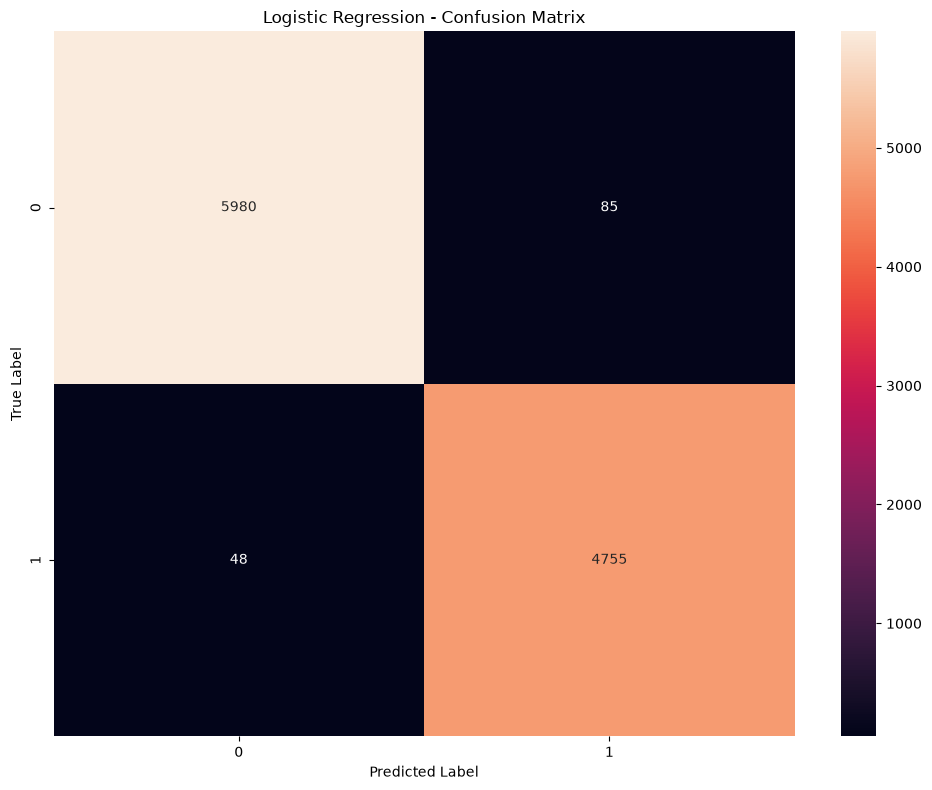

In [44]:
from sklearn.metrics import confusion_matrix  # Import the function that counts prediction outcomes.
import matplotlib.pyplot as plt  # Import Matplotlib chart functions as plt.
import seaborn as sns  # Import Seaborn statistical charts as sns.

cm = confusion_matrix(y_test, y_test_pred_lr)  # Count correct and incorrect predictions for each class pair.

plt.figure(figsize=(10, 8))  # Create a chart canvas before plotting data.

sns.heatmap(  # Draw confusion-matrix counts as a colored grid.
    cm,  # Pass confusion-matrix counts to the heatmap.
    annot=True,  # Write counts inside matrix cells.
    fmt="d",  # Display values as whole-number counts.
    xticklabels=sorted(y_test.unique()),  # Label columns with predicted classes.
    yticklabels=sorted(y_test.unique())  # Label rows with actual classes.
)  # Close the list, dictionary, or function call opened above.

plt.title("Logistic Regression - Confusion Matrix")  # Set the chart title.
plt.xlabel("Predicted Label")  # Label the horizontal axis.
plt.ylabel("True Label")  # Label the vertical axis.
plt.tight_layout()  # Adjust spacing so chart labels are not clipped.
plt.show()  # Render the chart in the notebook.

### 10. Add explainable email-security signals

This experiment adds URL counts and suspicious URL patterns (shorteners, IP-address hosts, punycode, user information, deep subdomains, and unusually long domains), urgency phrases, and requests for passwords, verification codes, or financial details. These signals join the existing word TF-IDF features in the same Logistic Regression pipeline. They are evidence features, not independent rules that force a verdict.

In [ ]:
import sys  # Import Python's module search-path controls.
from pathlib import Path  # Import Path for file and folder locations.

PROJECT_DIR = Path.cwd()  # Find the project folder containing the Flask/model code.
if not (PROJECT_DIR / "phishing_detector.py").exists():  # Check whether the notebook is already running from the project folder.
    PROJECT_DIR = PROJECT_DIR.parent  # Find the project folder containing the Flask/model code.
sys.path.insert(0, str(PROJECT_DIR))  # Add the project folder so Python can import its module.

from phishing_detector import EmailSecurityFeatures  # Import the same security-feature extractor used by the website.

example_email = (    "URGENT: action required within 5 minutes. "  # Create a sample email to demonstrate signal extraction.
    "Visit http://bit.ly/account and https://192.0.2.10/login. "  # Add a shortener URL and IP-address URL to the example email.
    "Enter your password and verification code to avoid suspension."  # Add credential-request and urgency wording to the example email.
)  # Close the list, dictionary, or function call opened above.
security_extractor = EmailSecurityFeatures()  # Create the website's email-security feature extractor.
example_signals = pd.DataFrame(  # Put the sample email's signals in a readable table.
    security_extractor.transform([example_email]).toarray(),  # Extract security signals and convert them into a regular numeric array.
    columns=security_extractor.get_feature_names_out(),  # Use extracted feature names as the table row labels.
    index=["example email"],  # Label the signal table row so the sample is easy to recognize.
)  # Close the list, dictionary, or function call opened above.
display(example_signals.T.rename(columns={"example email": "count / flag"}))  # Show this table or preview in the notebook output.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer  # Import the text-to-numeric TF-IDF feature converter.
from sklearn.linear_model import LogisticRegression  # Import the classifier used to learn phishing patterns.
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score  # Import the function that counts prediction outcomes.
from sklearn.pipeline import FeatureUnion, Pipeline  # Import tools for combining features and chaining model steps.
from sklearn.preprocessing import MaxAbsScaler  # Import a scaler for the numeric security indicators.
import joblib  # Import tools for saving and loading trained pipelines.

combined_features = FeatureUnion([  # Join word TF-IDF and numeric security features.
    ("word_tfidf", TfidfVectorizer(  # Add the word-based TF-IDF feature branch.
        lowercase=True,  # Lowercase text before extracting words.
        stop_words=None,  # Keep common words instead of removing them.
        ngram_range=(1, 2),  # Use single words and two-word phrases.
        min_df=2,  # Ignore words seen in fewer than two training emails.
        max_df=0.98,  # Ignore words seen in more than 98% of training emails.
        sublinear_tf=True,  # Reduce the influence of repeated words.
        max_features=200000,  # Limit the vocabulary to 200,000 features.
    )),  # Close the list, dictionary, or function call opened above.
    ("email_security_signals", Pipeline([  # Add the numeric email-security feature branch.
        ("extract", EmailSecurityFeatures()),  # Run the custom security-signal extractor.
        ("scale", MaxAbsScaler()),  # Scale numeric security signals before classification.
    ])),  # Close the numeric-signal branch and its Pipeline/FeatureUnion entries.
])  # Close the list, dictionary, or function call opened above.

email_security_pipeline = Pipeline([  # Combine feature extraction and Logistic Regression into one model.
    ("features", combined_features),  # Connect feature extraction to the model pipeline.
    ("classifier", LogisticRegression(  # Add Logistic Regression as the final pipeline step.
        C=2.0,  # Set Logistic Regression regularization strength.
        max_iter=2000,  # Allow up to 2,000 optimization steps.
        solver="saga",  # Use the SAGA optimization method.
        class_weight="balanced",  # Balance the influence of the two classes.
        random_state=42,  # Use a fixed seed for repeatable results.
        n_jobs=-1,  # Use all available CPU cores where supported.
    )),  # Close the list, dictionary, or function call opened above.
])  # Close the list, dictionary, or function call opened above.
email_security_pipeline.fit(X_train, y_train)  # Train the enhanced website pipeline on raw email text and labels.
def summarize_binary_predictions(split_name, model_name, actual, predicted):  # Define a function that calculates classification metrics.
    tn, fp, fn, tp = confusion_matrix(actual, predicted, labels=[0, 1]).ravel()  # Unpack counts for correct/incorrect benign and phishing predictions.
    return {  # Return the prepared result to the code that called this helper.
        "split": split_name,  # Record whether these metrics describe validation or test data.
        "model": model_name,  # Record which model version produced these metrics.
        "rows": len(actual),  # Record the number of evaluated emails.
        "accuracy": accuracy_score(actual, predicted),  # Record the fraction of predictions that are correct.
        "macro_f1": f1_score(actual, predicted, average="macro"),  # Record F1 averaged equally across both classes.
        "phishing_precision": precision_score(actual, predicted, pos_label=1, zero_division=0),  # Record how often phishing predictions are actually phishing.
        "phishing_recall": recall_score(actual, predicted, pos_label=1, zero_division=0),  # Record how many actual phishing emails are detected.
        "tn": tn,  # Record benign emails correctly predicted as benign.
        "fp": fp,  # Record benign emails incorrectly predicted as phishing.
        "fn": fn,  # Record phishing emails incorrectly predicted as benign.
        "tp": tp,  # Record phishing emails correctly predicted as phishing.
    }  # Close the list, dictionary, or function call opened above.

validation_test_rows = []  # Start collecting model comparison results.
for split_name, texts, actual, baseline_features in [  # Evaluate both models on validation and held-out test partitions.
    ("validation", X_val, y_val, X_val_tfidf),  # Add the validation partition for model comparison.
    ("heldout_test", X_test, y_test, X_test_tfidf),  # Add the held-out test partition for model comparison.
]:  # Finish listing the partitions/models in this comparison loop.
    baseline_predictions = lr_1.predict(baseline_features)  # Predict with the word-only baseline for this split.
    enhanced_predictions = email_security_pipeline.predict(texts)  # Predict with the website model and its extra security signals.
    validation_test_rows.append(summarize_binary_predictions(  # Add this model's scores to the comparison list.
        split_name, "word_tfidf_baseline", actual, baseline_predictions  # Summarize baseline performance for this partition.
    ))  # Close the list, dictionary, or function call opened above.
    validation_test_rows.append(summarize_binary_predictions(  # Add this model's scores to the comparison list.
        split_name, "word_tfidf_plus_email_signals", actual, enhanced_predictions  # Summarize enhanced-model performance for this partition.
    ))  # Close the list, dictionary, or function call opened above.

feature_model_comparison = pd.DataFrame(validation_test_rows)  # Collect the model comparison rows in a DataFrame.
display(feature_model_comparison.round(6))  # Show this table or preview in the notebook output.

model_dir = PROJECT_DIR / "models"  # Choose the folder where model artifacts will be written.
model_dir.mkdir(parents=True, exist_ok=True)  # Create the model-output folder if it does not exist.
baseline_pipeline = Pipeline([("tfidf", tfidf), ("classifier", lr_1)])  # Package the fitted word vectorizer and baseline classifier together.
baseline_model_path = model_dir / "email_classifier_word_tfidf_baseline.pkl"  # Set the save path for the word-only comparison model.
website_model_path = model_dir / "email_classifier.pkl"  # Set the save path for the website's model.
joblib.dump(baseline_pipeline, baseline_model_path)  # Save a trained pipeline to a pickle file.
joblib.dump(email_security_pipeline, website_model_path)  # Save a trained pipeline to a pickle file.

feature_model_comparison.to_csv(  # Save the comparison table as a CSV file.
    PROJECT_DIR / "training" / "MeAJOR_feature_engineering_validation_test.csv",  # Set the output path for the validation/test comparison CSV.
    index=False,  # Do not save row numbers in the CSV.
)  # Close the list, dictionary, or function call opened above.

reloaded_email_model = joblib.load(website_model_path)  # Load the saved website pipeline again to check it.
reloaded_probabilities = reloaded_email_model.predict_proba([X_test.iloc[0]])  # Check the saved model’s probabilities on one held-out email.
assert reloaded_probabilities.shape == (1, 2)  # Check that the saved model returns valid class probabilities.
assert abs(float(reloaded_probabilities[0].sum()) - 1.0) < 1e-3  # Check that the saved model returns valid class probabilities.
print(f"Saved baseline: {baseline_model_path}")
print(f"Saved enhanced website model: {website_model_path}")
print("Reloaded artifact prediction:", int(reloaded_email_model.predict([X_test.iloc[0]])[0]))
print("Classes:", reloaded_email_model.classes_.tolist())